# CAI421 — xBD Building Damage 
This notebook prepares paired xBD building images, creates the train/validation/test splits, applies environmental degradations, trains the baseline and Siamese models, and evaluates their classification performance and robustness.



## Data Preparation
Preparing and splitting the xBD dataset.

## Image Degradation
Applying four types of image degradation.

## Data Visualization
Displaying sample images.

## Model Implementation
Building Baseline and Siamese ResNet-50 models.

## Model Training
Training both models.

## Model Evaluation
Evaluating models on clean and degraded images.

## Results
Comparing and saving model results.

## 1. Environment Setup and Configuration

This cell imports the required libraries, mounts Google Drive, sets the random seed, and defines the dataset paths and project configuration.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import io
import json
import time
import tarfile
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
from collections import Counter
from shapely import wkt
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ARCHIVE_PATH = Path(
    "/content/drive/MyDrive/CAI421_Project/xBD/archives/train_images_labels_targets.tar"
)
# Work on Colab's local disk (fast). Final results are copied to Drive in the last cell.
PROJECT_DIR = Path("/content/final_data")
DRIVE_RESULTS_DIR = Path("/content/drive/MyDrive/CAI421_final_results_v2")
CROP_DIR = PROJECT_DIR / "building_crops"
PRE_DIR = CROP_DIR / "pre"
POST_DIR = CROP_DIR / "post"
DEGRADED_DIR = PROJECT_DIR / "degraded"
SPLIT_DIR = PROJECT_DIR / "splits"

MANIFEST_PATH = PROJECT_DIR / "building_manifest.csv"
SPLIT_MANIFEST_PATH = PROJECT_DIR / "building_manifest_with_splits.csv"
SUMMARY_PATH = PROJECT_DIR / "dataset_summary.csv"

VALID_CLASSES = ["no-damage", "minor-damage", "major-damage", "destroyed"]
MAX_PAIRS = 600  # stratified by disaster, fixed seed
MAX_BUILDINGS_PER_PAIR = 10
CROP_SIZE = 512

for folder in [PROJECT_DIR, PRE_DIR, POST_DIR, DEGRADED_DIR, SPLIT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

assert ARCHIVE_PATH.exists(), f"Archive not found: {ARCHIVE_PATH}"

import torch
if not torch.cuda.is_available():
    print("WARNING: no GPU. Go to Runtime > Change runtime type > T4 GPU, then restart.")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

print("Setup complete.")
print("Archive size (GiB):", round(ARCHIVE_PATH.stat().st_size / (1024**3), 3))
print("Output directory:", PROJECT_DIR)
print("Maximum image pairs:", MAX_PAIRS)
print("Maximum crops per pair:", MAX_BUILDINGS_PER_PAIR)
print("Random seed:", SEED)

Mounted at /content/drive
GPU: Tesla T4
Setup complete.
Archive size (GiB): 7.806
Output directory: /content/final_data
Maximum image pairs: 600
Maximum crops per pair: 10
Random seed: 42


## 2. Dataset Archive Preparation

This cell checks the available storage space and creates a local copy of the xBD archive to improve data access and processing speed.

In [ ]:
local_archive = Path("/content/xbd_train_images_labels_targets.tar")
source_size = ARCHIVE_PATH.stat().st_size
free_bytes = shutil.disk_usage("/content").free

if free_bytes > source_size + 500_000_000:
    if not local_archive.exists() or local_archive.stat().st_size != source_size:
        print("Copying archive to local Colab storage. Please wait...")
        started = time.time()
        chunk_size = 128 * 1024 * 1024
        copied = 0
        with open(ARCHIVE_PATH, "rb") as src, open(local_archive, "wb") as dst:
            while True:
                chunk = src.read(chunk_size)
                if not chunk:
                    break
                dst.write(chunk)
                copied += len(chunk)
                print(
                    f"Copied {copied / (1024**3):.2f} / {source_size / (1024**3):.2f} GiB",
                    end="\r"
                )
        print(f"\nLocal copy completed in {(time.time() - started) / 60:.1f} minutes.")
    archive_to_use = local_archive
else:
    print("Not enough free local disk space for a full copy.")
    print("Using Drive archive directly; reading may be slow.")
    archive_to_use = ARCHIVE_PATH

print("Opening archive and indexing files...")
started = time.time()
tar = tarfile.open(archive_to_use, mode="r:*")
members = {
    member.name: member
    for member in tar.getmembers()
    if member.isfile()
}
print(f"Indexed {len(members)} files in {(time.time() - started) / 60:.1f} minutes.")

post_names = sorted(
    name for name in members
    if name.startswith("train/images/") and name.endswith("_post_disaster.png")
)

matched_pairs = []
for post_name in post_names:
    pre_name = post_name.replace("_post_disaster.png", "_pre_disaster.png")
    label_name = (
        post_name.replace("train/images/", "train/labels/")
        .replace(".png", ".json")
    )
    if pre_name in members and label_name in members:
        matched_pairs.append((pre_name, post_name, label_name))

# Stratified sample: each disaster keeps its share of the pairs (fixed seed)
from collections import defaultdict
by_disaster = defaultdict(list)
for pair in sorted(matched_pairs):
    disaster = Path(pair[1]).name.rsplit("_", 3)[0]
    by_disaster[disaster].append(pair)

total = len(matched_pairs)
quotas = {d: MAX_PAIRS * len(p) / total for d, p in by_disaster.items()}
counts = {d: int(q) for d, q in quotas.items()}
for d in sorted(quotas, key=lambda d: quotas[d] - counts[d], reverse=True)[: MAX_PAIRS - sum(counts.values())]:
    counts[d] += 1

selected_pairs = []
for d in sorted(by_disaster):
    pairs = by_disaster[d][:]
    random.Random(f"{SEED}_{d}").shuffle(pairs)
    selected_pairs.extend(pairs[: counts[d]])
random.Random(SEED).shuffle(selected_pairs)

print("Pairs per disaster:", {d: counts[d] for d in sorted(counts)})

print("Available matched pairs:", len(matched_pairs))
print("Selected pairs:", len(selected_pairs))

Copying archive to local Colab storage. Please wait...
Copied 7.81 / 7.81 GiB
Local copy completed in 4.5 minutes.
Opening archive and indexing files...
Indexed 16794 files in 1.0 minutes.
Pairs per disaster: {'guatemala-volcano': 4, 'hurricane-florence': 68, 'hurricane-harvey': 68, 'hurricane-matthew': 51, 'hurricane-michael': 74, 'mexico-earthquake': 26, 'midwest-flooding': 60, 'palu-tsunami': 24, 'santa-rosa-wildfire': 49, 'socal-fire': 176}
Available matched pairs: 2799
Selected pairs: 600


## 3. Extract Selected Dataset Files

This cell extracts the required pre-disaster images, post-disaster images, and annotation files from the xBD archive.

In [ ]:
# Fast extraction: read the archive ONCE from start to end and keep only the selected files
needed = {name for pair in selected_pairs for name in pair}
LOCAL_FILES = Path("/content/xbd_selected")
LOCAL_FILES.mkdir(parents=True, exist_ok=True)

started = time.time()
found = 0
with tarfile.open(archive_to_use, mode="r|*") as stream:
    for member in stream:
        if member.name in needed:
            out = LOCAL_FILES / member.name
            out.parent.mkdir(parents=True, exist_ok=True)
            with stream.extractfile(member) as src, open(out, "wb") as dst:
                shutil.copyfileobj(src, dst)
            found += 1
            if found % 200 == 0:
                print(f"Extracted {found}/{len(needed)} files", end="\r")
print(f"\nExtracted {found}/{len(needed)} files in {(time.time() - started) / 60:.1f} minutes.")

class LocalFiles:
    def extractfile(self, name):
        return open(LOCAL_FILES / name, "rb")

tar = LocalFiles()
members = {name: name for name in needed}
print("Ready. Now run Cell 3 and everything below it.")



Extracted 1800/1800 files in 1.0 minutes.
Ready. Now run Cell 3 and everything below it.


## 4. Building Crop Extraction

This cell extracts building image crops from the satellite images, assigns damage labels, and creates a manifest containing the extracted samples.

In [ ]:
manifest = []
failed_pairs = 0
started_all = time.time()

for pair_num, (pre_name, post_name, label_name) in enumerate(selected_pairs, start=1):
    try:
        with tar.extractfile(members[pre_name]) as f:
            pre_image = Image.open(f).convert("RGB")
        with tar.extractfile(members[post_name]) as f:
            post_image = Image.open(f).convert("RGB")
        with tar.extractfile(members[label_name]) as f:
            annotation = json.load(f)

        pair_id = Path(post_name).name.replace("_post_disaster.png", "")
        features = annotation.get("features", {}).get("xy", [])

        candidates = []
        for feature in features:
            props = feature.get("properties", {})
            label = props.get("subtype")
            polygon_text = feature.get("wkt")
            if label not in VALID_CLASSES or not polygon_text:
                continue
            try:
                polygon = wkt.loads(polygon_text)
                if not polygon.is_empty:
                    candidates.append((label, polygon))
            except Exception:
                continue

        pair_rng = random.Random(f"{SEED}_{pair_id}")
        pair_rng.shuffle(candidates)
        candidates = candidates[:MAX_BUILDINGS_PER_PAIR]

        width, height = post_image.size
        if width < CROP_SIZE or height < CROP_SIZE:
            raise ValueError(f"Image dimensions {width}x{height} smaller than crop size.")

        for idx, (label, polygon) in enumerate(candidates):
            min_x, min_y, max_x, max_y = polygon.bounds
            cx = (min_x + max_x) / 2
            cy = (min_y + max_y) / 2
            half = CROP_SIZE // 2

            left = max(0, min(int(cx - half), width - CROP_SIZE))
            top = max(0, min(int(cy - half), height - CROP_SIZE))
            right, bottom = left + CROP_SIZE, top + CROP_SIZE

            sample_id = f"{pair_id}_{idx:03d}"
            pre_path = PRE_DIR / f"{sample_id}.jpg"
            post_path = POST_DIR / f"{sample_id}.jpg"

            pre_image.crop((left, top, right, bottom)).save(
                pre_path, format="JPEG", quality=88
            )
            post_image.crop((left, top, right, bottom)).save(
                post_path, format="JPEG", quality=88
            )

            manifest.append({
                "sample_id": sample_id,
                "pair_id": pair_id,
                "label": label,
                "pre_image": str(pre_path),
                "post_image": str(post_path)
            })

        pre_image.close()
        post_image.close()

    except Exception as e:
        failed_pairs += 1
        print(f"Pair {pair_num} skipped: {e}")

    if pair_num % 10 == 0 or pair_num == len(selected_pairs):
        pd.DataFrame(manifest).to_csv(MANIFEST_PATH, index=False)
        print(
            f"Processed {pair_num}/{len(selected_pairs)} pairs | "
            f"saved building samples: {len(manifest)}"
        )

manifest_df = pd.DataFrame(manifest)
manifest_df.to_csv(MANIFEST_PATH, index=False)

print("\nEXTRACTION COMPLETE")
print("Pairs selected:", len(selected_pairs))
print("Pairs failed:", failed_pairs)
print("Total building samples:", len(manifest_df))
if not manifest_df.empty:
    print("\nClass distribution:")
    print(manifest_df["label"].value_counts().reindex(VALID_CLASSES, fill_value=0))
print("Manifest saved to:", MANIFEST_PATH)
print("Elapsed minutes:", round((time.time() - started_all) / 60, 2))

Processed 10/600 pairs | saved building samples: 49
Processed 20/600 pairs | saved building samples: 103
Processed 30/600 pairs | saved building samples: 158
Processed 40/600 pairs | saved building samples: 208
Processed 50/600 pairs | saved building samples: 285
Processed 60/600 pairs | saved building samples: 359
Processed 70/600 pairs | saved building samples: 428
Processed 80/600 pairs | saved building samples: 471
Processed 90/600 pairs | saved building samples: 555
Processed 100/600 pairs | saved building samples: 624
Processed 110/600 pairs | saved building samples: 701
Processed 120/600 pairs | saved building samples: 776
Processed 130/600 pairs | saved building samples: 859
Processed 140/600 pairs | saved building samples: 937
Processed 150/600 pairs | saved building samples: 998
Processed 160/600 pairs | saved building samples: 1075
Processed 170/600 pairs | saved building samples: 1143
Processed 180/600 pairs | saved building samples: 1214
Processed 190/600 pairs | saved bui

## 5. Dataset Splitting

This cell divides the dataset into training, validation, and test sets using Stratified Group K-Fold to maintain class distribution and prevent image-pair leakage.

In [ ]:

import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold
from pathlib import Path

SEED = 42

data_dir = PROJECT_DIR
manifest_path = data_dir / "building_manifest.csv"
output_path = data_dir / "building_manifest_with_splits.csv"

df = pd.read_csv(manifest_path)

# Identify the label column
label_candidates = [
    "label", "damage_label", "damage_class",
    "damage_type", "class"
]
label_col = next(
    (col for col in label_candidates if col in df.columns),
    None
)

if label_col is None:
    raise ValueError(
        f"Cannot identify the damage-label column. "
        f"Available columns: {df.columns.tolist()}"
    )

if "pair_id" not in df.columns:
    raise ValueError("The manifest must contain a pair_id column.")

# Generate group-aware folds
X = np.zeros(len(df))
y = df[label_col].astype(str)
groups = df["pair_id"]

outer_cv = StratifiedGroupKFold(
    n_splits=6, shuffle=True, random_state=SEED
)
outer_folds = list(outer_cv.split(X, y, groups))

# Search possible group-preserving train/validation/test splits
best_score = float("inf")
best_assignment = None

overall_dist = y.value_counts(normalize=True).sort_index()
target_ratios = {"train": 0.68, "validation": 0.15, "test": 0.17}

for test_fold, (remaining_idx, test_idx) in enumerate(outer_folds):
    remaining_df = df.iloc[remaining_idx].reset_index(drop=True)
    remaining_y = y.iloc[remaining_idx].reset_index(drop=True)
    remaining_groups = groups.iloc[remaining_idx].reset_index(drop=True)

    inner_cv = StratifiedGroupKFold(
        n_splits=5, shuffle=True, random_state=SEED
    )

    inner_folds = list(
        inner_cv.split(
            np.zeros(len(remaining_df)),
            remaining_y,
            remaining_groups
        )
    )

    for val_fold, (train_rel, val_rel) in enumerate(inner_folds):
        train_idx = remaining_idx[train_rel]
        val_idx = remaining_idx[val_rel]

        assignment = np.full(len(df), "", dtype=object)
        assignment[train_idx] = "train"
        assignment[val_idx] = "validation"
        assignment[test_idx] = "test"

        score = 0.0

        for split_name, target_ratio in target_ratios.items():
            split_idx = np.where(assignment == split_name)[0]
            split_y = y.iloc[split_idx]

            # Penalize split sizes that differ from the targets
            actual_ratio = len(split_idx) / len(df)
            score += 2 * abs(actual_ratio - target_ratio)

            # Encourage class proportions similar to the full dataset
            split_dist = (
                split_y.value_counts(normalize=True)
                .reindex(overall_dist.index, fill_value=0)
            )
            score += sum(
                abs(split_dist[c] - overall_dist[c])
                for c in overall_dist.index
            )

        if score < best_score:
            best_score = score
            best_assignment = assignment.copy()

if best_assignment is None:
    raise RuntimeError("Could not create a valid data split.")

df["split"] = best_assignment

# Verify that each image pair belongs to only one split
pair_split_counts = df.groupby("pair_id")["split"].nunique()
assert pair_split_counts.max() == 1, "Data leakage detected!"

df.to_csv(output_path, index=False)

print("Saved split manifest:", output_path)
print("\nSample counts:")
print(df["split"].value_counts())

print("\nClass distribution by split:")
print(pd.crosstab(df["split"], df[label_col], margins=True))

print("\nClass percentages by split:")
print(
    pd.crosstab(
        df["split"], df[label_col], normalize="index"
    ).round(3) * 100
)

print("\nUnique image pairs by split:")
print(df.groupby("split")["pair_id"].nunique())

print("\nPair-level leakage check: PASSED")
print("Seed:", SEED)


Saved split manifest: /content/final_data/building_manifest_with_splits.csv

Sample counts:
split
train         2756
test           707
validation     626
Name: count, dtype: int64

Class distribution by split:
label       destroyed  major-damage  minor-damage  no-damage   All
split                                                             
test              105            86            81        435   707
train             455           324           283       1694  2756
validation         73            78            80        395   626
All               633           488           444       2524  4089

Class percentages by split:
label       destroyed  major-damage  minor-damage  no-damage
split                                                       
test             14.9          12.2          11.5       61.5
train            16.5          11.8          10.3       61.5
validation       11.7          12.5          12.8       63.1

Unique image pairs by split:
split
test           83

## 6. Environmental Degradation Methods

This cell defines four degradation methods: Gaussian Noise, Atmospheric Blur, Resolution Reduction, and Compression Artifacts.

In [ ]:
import numpy as np
import pandas as pd
import albumentations as A
from PIL import Image

def apply_degradation(image, kind, seed_value):
    arr = np.array(image.convert("RGB"))

    if kind == "gaussian_noise":
        transform = A.GaussNoise(
            std_range=(18 / 255, 18 / 255),
            mean_range=(0, 0),
            p=1.0
        )

    elif kind == "atmospheric_blur":
        transform = A.GaussianBlur(
            blur_limit=(3, 5),
            sigma_limit=(0.5, 2.0),
            p=1.0
        )

    elif kind == "resolution_reduction":
        transform = A.Downscale(
            scale_range=(0.25, 0.25),
            interpolation_pair={
                "downscale": 1,
                "upscale": 1
            },
            p=1.0
        )

    elif kind == "compression_artifacts":
        transform = A.ImageCompression(
            quality_range=(20, 20),
            compression_type="jpeg",
            p=1.0
        )

    else:
        raise ValueError(f"Unknown degradation type: {kind}")

    pipeline = A.Compose([transform], seed=seed_value)
    result = pipeline(image=arr)["image"]

    return Image.fromarray(result)


degradation_types = [
    "gaussian_noise",
    "atmospheric_blur",
    "resolution_reduction",
    "compression_artifacts"
]

split_df = pd.read_csv(SPLIT_MANIFEST_PATH)

print("Samples:", len(split_df))
print("Expected degraded images:", len(split_df) * 2 * len(degradation_types))
print("Albumentations version:", A.__version__)

Samples: 4089
Expected degraded images: 32712
Albumentations version: 2.0.8


## 7. Generate Degraded Images

This cell applies the four degradation methods to both pre-disaster and post-disaster building images and saves the resulting images separately.

In [ ]:


from pathlib import Path
from PIL import Image

DEGRADED_DIR_ALB = PROJECT_DIR / "degraded_albumentations"

created = 0
errors = []

for _, row in split_df.iterrows():
    for view in ["pre", "post"]:
        source_path = Path(row[f"{view}_image"])

        if not source_path.exists():
            errors.append(f"Missing source: {source_path}")
            continue

        with Image.open(source_path) as img:
            original = img.convert("RGB")

            for kind in degradation_types:
                out_dir = DEGRADED_DIR_ALB / kind / view
                out_dir.mkdir(parents=True, exist_ok=True)

                out_path = out_dir / f"{row['sample_id']}.jpg"

                seed_value = SEED + sum(
                    ord(ch)
                    for ch in f"{row['sample_id']}_{view}_{kind}"
                )

                try:
                    degraded = apply_degradation(
                        original, kind, seed_value
                    )

                    degraded.save(
                        out_path,
                        format="JPEG",
                        quality=95
                    )
                    degraded.close()
                    created += 1

                except Exception as e:
                    errors.append(
                        f"{row['sample_id']} | {view} | {kind} | {e}"
                    )

            original.close()

print("New images created:", created)
print("Errors:", len(errors))

for error in errors[:10]:
    print(error)

New images created: 32712
Errors: 0


## 8. Verify Degraded Images

This cell checks the number of generated degraded images and verifies that the expected files were created successfully.

In [ ]:
from pathlib import Path
from PIL import Image

total_images = 0

for kind in degradation_types:
    print(f"\n{kind}")
    kind_total = 0

    for view in ["pre", "post"]:
        folder = DEGRADED_DIR_ALB / kind / view
        files = list(folder.glob("*.jpg"))

        valid = 0
        for file in files:
            try:
                with Image.open(file) as img:
                    img.verify()
                valid += 1
            except Exception:
                print("Invalid image:", file.name)

        print(f"{view}: {len(files)} files, {valid} valid")
        kind_total += len(files)

    print("Total:", kind_total)
    total_images += kind_total

print("\nGrand total:", total_images)
print("Expected total:", len(split_df) * 2 * len(degradation_types))



gaussian_noise
pre: 4089 files, 4089 valid
post: 4089 files, 4089 valid
Total: 8178

atmospheric_blur
pre: 4089 files, 4089 valid
post: 4089 files, 4089 valid
Total: 8178

resolution_reduction
pre: 4089 files, 4089 valid
post: 4089 files, 4089 valid
Total: 8178

compression_artifacts
pre: 4089 files, 4089 valid
post: 4089 files, 4089 valid
Total: 8178

Grand total: 32712
Expected total: 32712


## 9. Inspect Dataset Manifest

This cell loads the dataset manifest and displays its columns, sample counts, and class distribution across the data splits.

In [ ]:

import pandas as pd
from pathlib import Path

df = pd.read_csv(SPLIT_MANIFEST_PATH)

print("Total samples:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nSplit counts:")
print(df["split"].value_counts())

print("\nClass counts by split:")
print(pd.crosstab(df["split"], df["label"]))

print("\nMissing values:")
print(df[["sample_id", "pre_image", "post_image", "label", "split"]]
      .isnull().sum())

print("\nDuplicate sample IDs:", df["sample_id"].duplicated().sum())
print("Unique image pairs:", df["pair_id"].nunique())

print("\nDegraded folder:", DEGRADED_DIR_ALB)


Total samples: 4089

Columns:
['sample_id', 'pair_id', 'label', 'pre_image', 'post_image', 'split']

Split counts:
split
train         2756
test           707
validation     626
Name: count, dtype: int64

Class counts by split:
label       destroyed  major-damage  minor-damage  no-damage
split                                                       
test              105            86            81        435
train             455           324           283       1694
validation         73            78            80        395

Missing values:
sample_id     0
pre_image     0
post_image    0
label         0
split         0
dtype: int64

Duplicate sample IDs: 0
Unique image pairs: 473

Degraded folder: /content/final_data/degraded_albumentations


## 10. Data Leakage Verification

This cell checks whether image pairs appear in more than one dataset split to ensure proper separation between training, validation, and testing data.

In [ ]:

import pandas as pd

df = pd.read_csv(SPLIT_MANIFEST_PATH)

pair_split_counts = df.groupby("pair_id")["split"].nunique()
leaked_pairs = pair_split_counts[pair_split_counts > 1]

print("Unique pairs:", df["pair_id"].nunique())
print("Pairs appearing in multiple splits:", len(leaked_pairs))

print("\nSamples per split:")
print(df["split"].value_counts())

print("\nClass distribution (%):")
print(
    pd.crosstab(df["split"], df["label"], normalize="index")
    .mul(100)
    .round(2)
)

if len(leaked_pairs) == 0:
    print("\nPASS: No pair leakage detected.")
else:
    print("\nWARNING: Pair leakage detected.")
    print(leaked_pairs)


Unique pairs: 473
Pairs appearing in multiple splits: 0

Samples per split:
split
train         2756
test           707
validation     626
Name: count, dtype: int64

Class distribution (%):
label       destroyed  major-damage  minor-damage  no-damage
split                                                       
test            14.85         12.16         11.46      61.53
train           16.51         11.76         10.27      61.47
validation      11.66         12.46         12.78      63.10

PASS: No pair leakage detected.


## 11. Dataset Class and DataLoaders

This cell defines the paired-image dataset, image transformations, class labels, and DataLoaders required for model training and evaluation.

In [ ]:

import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path

df = pd.read_csv(SPLIT_MANIFEST_PATH)

CLASS_NAMES = [
    "no-damage",
    "minor-damage",
    "major-damage",
    "destroyed"
]

CLASS_TO_IDX = {
    name: idx for idx, name in enumerate(CLASS_NAMES)
}

IMAGE_SIZE = 224
BATCH_SIZE = 16

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class XBDPairDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        unknown_labels = (
            set(self.dataframe["label"].unique())
            - set(CLASS_TO_IDX.keys())
        )

        if unknown_labels:
            raise ValueError(
                f"Unknown labels: {unknown_labels}"
            )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["pre_image"]) as img:
            pre_image = img.convert("RGB")

        with Image.open(row["post_image"]) as img:
            post_image = img.convert("RGB")

        if self.transform:
            pre_image = self.transform(pre_image)
            post_image = self.transform(post_image)

        label = CLASS_TO_IDX[row["label"]]

        return pre_image, post_image, torch.tensor(
            label, dtype=torch.long
        )


train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

train_dataset = XBDPairDataset(train_df, image_transform)
val_dataset = XBDPairDataset(val_df, image_transform)
test_dataset = XBDPairDataset(test_df, image_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Classes:", CLASS_TO_IDX)

pre_batch, post_batch, label_batch = next(iter(train_loader))

print("\nPre batch shape:", pre_batch.shape)
print("Post batch shape:", post_batch.shape)
print("Label batch shape:", label_batch.shape)
print("Labels in first batch:", label_batch.tolist())
print("Device available:", "CUDA" if torch.cuda.is_available() else "CPU")


Train samples: 2756
Validation samples: 626
Test samples: 707
Classes: {'no-damage': 0, 'minor-damage': 1, 'major-damage': 2, 'destroyed': 3}

Pre batch shape: torch.Size([16, 3, 224, 224])
Post batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Labels in first batch: [0, 0, 3, 2, 0, 0, 0, 3, 0, 0, 0, 2, 0, 1, 0, 0]
Device available: CUDA


## 12. Degradation Verification

This cell compares an original image with its degraded version using pixel-level differences to verify that the degradation process changes the image.

In [ ]:

import numpy as np
from PIL import Image
from pathlib import Path

sample = split_df.iloc[0]
view = "post"

original_path = Path(sample[f"{view}_image"])

with Image.open(original_path) as img:
    original = np.array(img.convert("RGB"))

for kind in degradation_types:
    degraded_path = (
        DEGRADED_DIR_ALB
        / kind
        / view
        / f"{sample['sample_id']}.jpg"
    )

    with Image.open(degraded_path) as img:
        degraded = np.array(img.convert("RGB"))

    difference = np.abs(
        original.astype(np.float32)
        - degraded.astype(np.float32)
    )

    print(f"\n{kind}")
    print("Original shape:", original.shape)
    print("Degraded shape:", degraded.shape)
    print("Mean absolute pixel difference:",
          round(float(difference.mean()), 3))
    print("Changed pixels:", int(np.any(difference > 0, axis=2).sum()))



gaussian_noise
Original shape: (512, 512, 3)
Degraded shape: (512, 512, 3)
Mean absolute pixel difference: 10.112
Changed pixels: 262037

atmospheric_blur
Original shape: (512, 512, 3)
Degraded shape: (512, 512, 3)
Mean absolute pixel difference: 2.426
Changed pixels: 220888

resolution_reduction
Original shape: (512, 512, 3)
Degraded shape: (512, 512, 3)
Mean absolute pixel difference: 3.659
Changed pixels: 233594

compression_artifacts
Original shape: (512, 512, 3)
Degraded shape: (512, 512, 3)
Mean absolute pixel difference: 3.876
Changed pixels: 260272


## 13. Visual Comparison of Degraded Images

This cell displays original and degraded image samples to visually examine the effects of the four environmental degradation methods.

In [ ]:


import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image

sample = split_df.iloc[0]
view = "post"

original_path = Path(sample[f"{view}_image"])

with Image.open(original_path) as img:
    original = np.array(img.convert("RGB")).astype(np.float32)

results = []

for kind in degradation_types:
    degraded_path = (
        DEGRADED_DIR_ALB
        / kind
        / view
        / f"{sample['sample_id']}.jpg"
    )

    with Image.open(degraded_path) as img:
        degraded = np.array(img.convert("RGB")).astype(np.float32)

    difference = np.abs(original - degraded)

    results.append({
        "Degradation": kind,
        "Mean Absolute Pixel Difference": round(
            float(difference.mean()), 3
        ),
        "Changed Pixels": int(
            np.any(difference > 0, axis=2).sum()
        )
    })

verification_df = pd.DataFrame(results)

verification_path = PROJECT_DIR / "degradation_verification.csv"
verification_df.to_csv(verification_path, index=False)

print("Verification results saved successfully.")
print(verification_df.to_string(index=False))
print("\nFile:", verification_path)


Verification results saved successfully.
          Degradation  Mean Absolute Pixel Difference  Changed Pixels
       gaussian_noise                          10.112          262037
     atmospheric_blur                           2.426          220888
 resolution_reduction                           3.659          233594
compression_artifacts                           3.876          260272

File: /content/final_data/degradation_verification.csv


## 14. Dataset Summary and Quality Checks

This cell summarizes the dataset, including class distribution, split counts, missing values, duplicate samples, and degraded image validity.

In [ ]:

from pathlib import Path
import pandas as pd
from PIL import Image

manifest = pd.read_csv(SPLIT_MANIFEST_PATH)

print("=== DATASET SUMMARY ===")
print("Total building samples:", len(manifest))
print("Unique image pairs:", manifest["pair_id"].nunique())
print("\nClass distribution:")
print(manifest["label"].value_counts().to_string())

print("\nSplit distribution:")
print(manifest["split"].value_counts().to_string())

print("\n=== DATA QUALITY CHECKS ===")
print("Missing values:", int(manifest.isnull().sum().sum()))
print("Duplicate sample IDs:", int(manifest["sample_id"].duplicated().sum()))

pair_split_counts = manifest.groupby("pair_id")["split"].nunique()
print("Pairs appearing in multiple splits:", int((pair_split_counts > 1).sum()))

print("\n=== DEGRADATION FILE CHECK ===")
expected_per_view = len(manifest)
total_files = 0

for kind in degradation_types:
    for view in ["pre", "post"]:
        folder = DEGRADED_DIR_ALB / kind / view
        files = list(folder.glob("*.jpg")) if folder.exists() else []
        valid_files = 0

        for file_path in files:
            try:
                with Image.open(file_path) as img:
                    img.verify()
                valid_files += 1
            except Exception:
                pass

        total_files += valid_files
        print(
            f"{kind} | {view}: "
            f"{valid_files}/{expected_per_view} valid images"
        )

expected_total = len(manifest) * 2 * len(degradation_types)

print("\nTotal valid degraded images:", total_files)
print("Expected degraded images:", expected_total)
print("All checks passed:", total_files == expected_total)


=== DATASET SUMMARY ===
Total building samples: 4089
Unique image pairs: 473

Class distribution:
label
no-damage       2524
destroyed        633
major-damage     488
minor-damage     444

Split distribution:
split
train         2756
test           707
validation     626

=== DATA QUALITY CHECKS ===
Missing values: 0
Duplicate sample IDs: 0
Pairs appearing in multiple splits: 0

=== DEGRADATION FILE CHECK ===
gaussian_noise | pre: 4089/4089 valid images
gaussian_noise | post: 4089/4089 valid images
atmospheric_blur | pre: 4089/4089 valid images
atmospheric_blur | post: 4089/4089 valid images
resolution_reduction | pre: 4089/4089 valid images
resolution_reduction | post: 4089/4089 valid images
compression_artifacts | pre: 4089/4089 valid images
compression_artifacts | post: 4089/4089 valid images

Total valid degraded images: 32712
Expected degraded images: 32712
All checks passed: True


## 15. Dataset Visualization

This cell generates visual summaries of the dataset and displays representative image samples to support data inspection and analysis.

CLASS DISTRIBUTION


,class,samples
0,no-damage,2524
1,minor-damage,444
2,major-damage,488
3,destroyed,633



SPLIT COUNTS


,split,samples
0,train,2756
1,test,707
2,validation,626



SUMMARY


,metric,value
0,total_building_samples,4089
1,unique_image_pairs,473
2,pre_crop_files,4089
3,post_crop_files,4089
4,train_samples,2756
5,validation_samples,626
6,test_samples,707


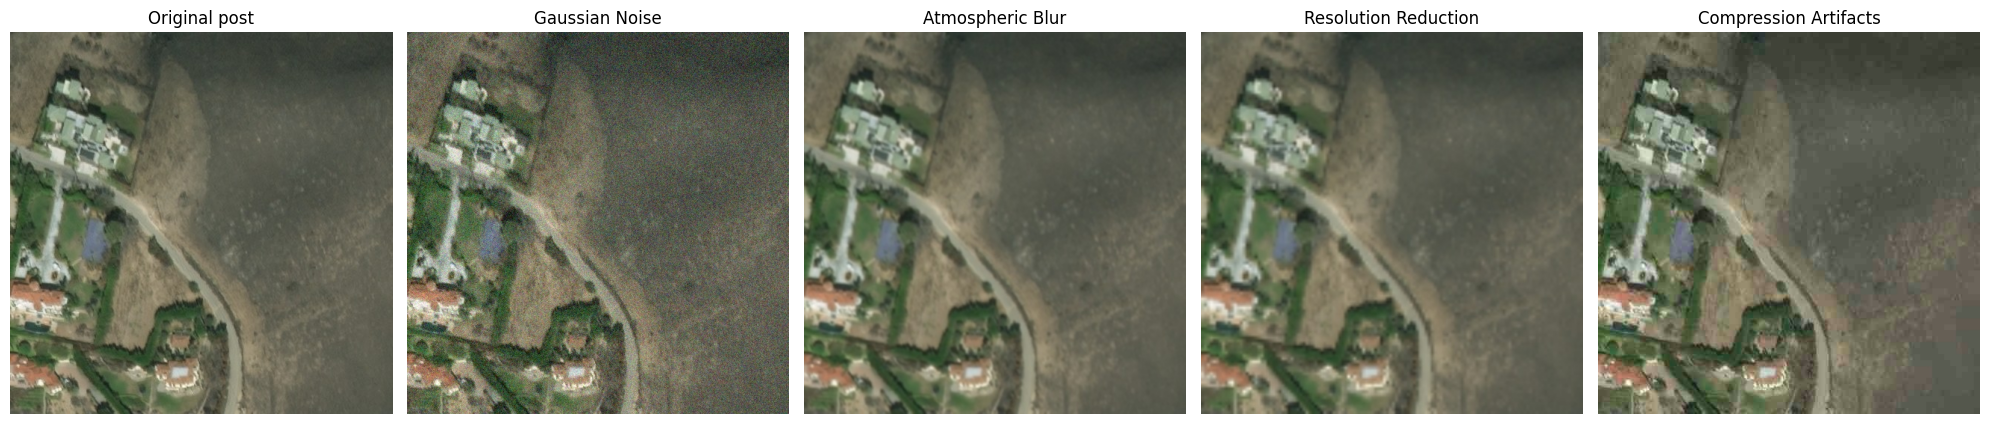


Saved summary files:
/content/final_data/building_manifest.csv
/content/final_data/building_manifest_with_splits.csv
/content/final_data/class_distribution.csv
/content/final_data/split_class_distribution.csv
/content/final_data/dataset_summary.csv
Degraded images folder: /content/final_data/degraded_albumentations


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

manifest_df = pd.read_csv(MANIFEST_PATH)
split_df = pd.read_csv(SPLIT_MANIFEST_PATH)

DEGRADED_DIR_ALB = PROJECT_DIR / "degraded_albumentations"

class_counts = (
    manifest_df["label"].value_counts()
    .reindex(VALID_CLASSES, fill_value=0)
    .rename_axis("class")
    .reset_index(name="samples")
)

split_counts = (
    split_df.groupby(["split", "label"])
    .size()
    .reset_index(name="samples")
)

class_counts.to_csv(PROJECT_DIR / "class_distribution.csv", index=False)
split_counts.to_csv(PROJECT_DIR / "split_class_distribution.csv", index=False)

summary = pd.DataFrame({
    "metric": [
        "total_building_samples", "unique_image_pairs",
        "pre_crop_files", "post_crop_files",
        "train_samples", "validation_samples", "test_samples"
    ],
    "value": [
        len(manifest_df), manifest_df["pair_id"].nunique(),
        len(list(PRE_DIR.glob("*.jpg"))), len(list(POST_DIR.glob("*.jpg"))),
        int((split_df["split"] == "train").sum()),
        int((split_df["split"] == "validation").sum()),
        int((split_df["split"] == "test").sum())
    ]
})

summary.to_csv(SUMMARY_PATH, index=False)

print("CLASS DISTRIBUTION")
display(class_counts)

print("\nSPLIT COUNTS")
display(
    split_df["split"]
    .value_counts()
    .rename_axis("split")
    .reset_index(name="samples")
)

print("\nSUMMARY")
display(summary)

if not manifest_df.empty:
    row = manifest_df.iloc[0]
    examples = [("Original post", Path(row["post_image"]))]

    for kind in degradation_types:
        examples.append((
            kind.replace("_", " ").title(),
            DEGRADED_DIR_ALB / kind / "post" / f"{row['sample_id']}.jpg"
        ))

    fig, axes = plt.subplots(1, len(examples), figsize=(20, 5))

    for ax, (title, path) in zip(axes, examples):
        if path.exists():
            with Image.open(path) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(title)
        else:
            ax.set_title(f"{title}\nImage not found")

        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("\nSaved summary files:")
print(MANIFEST_PATH)
print(SPLIT_MANIFEST_PATH)
print(PROJECT_DIR / "class_distribution.csv")
print(PROJECT_DIR / "split_class_distribution.csv")
print(SUMMARY_PATH)
print("Degraded images folder:", DEGRADED_DIR_ALB)


## 16. Model Training Configuration

This cell configures the training environment, selects the available computing device, defines the damage classes, and sets the training parameters.

In [ ]:


import os
import time
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from pathlib import Path
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from torch.utils.data import DataLoader

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Use the exact class names from Cell 16
CLASS_NAMES = [
    "no-damage",
    "minor-damage",
    "major-damage",
    "destroyed"
]

NUM_CLASSES = len(CLASS_NAMES)

NUM_EPOCHS = 10        # maximum; early stopping usually ends sooner
LEARNING_RATE = 0.0001
PATIENCE = 3           # stop if validation macro F1 does not improve for 3 epochs

print("Device:", DEVICE)
print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)
print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Early stopping patience:", PATIENCE)
print("Random seed:", SEED)

assert len(train_dataset) > 0, "Training dataset is empty!"
assert len(val_dataset) > 0, "Validation dataset is empty!"
assert len(test_dataset) > 0, "Test dataset is empty!"

print("Training environment is ready.")

Device: cuda
Classes: ['no-damage', 'minor-damage', 'major-damage', 'destroyed']
Number of classes: 4
Epochs: 10
Learning rate: 0.0001
Early stopping patience: 3
Random seed: 42
Training environment is ready.


## 17. Model Architecture Implementation

This cell defines the Baseline ResNet-50 and the proposed Siamese ResNet-50 architecture using a shared backbone to extract features from paired images.

In [ ]:


def create_resnet50_backbone():
    try:
        backbone = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )
        print("ResNet-50 pretrained weights loaded.")

    except Exception as e:
        print("Pretrained weights unavailable:", e)
        print("Using ResNet-50 with random initialization.")

        backbone = models.resnet50(weights=None)

    feature_dim = backbone.fc.in_features
    backbone.fc = nn.Identity()

    return backbone, feature_dim


# Baseline: Single-input ResNet-50
class BaselineResNet50(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()

        self.backbone, feature_dim = create_resnet50_backbone()

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(feature_dim, num_classes)
        )

    def forward(self, x):
        features = self.backbone(x)
        return self.classifier(features)


# Proposed Model: Siamese ResNet-50
class SiameseResNet50(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()

        self.backbone, feature_dim = create_resnet50_backbone()

        self.classifier = nn.Sequential(
            nn.Linear(feature_dim * 2, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    def forward(self, pre_image, post_image):

        pre_features = self.backbone(pre_image)
        post_features = self.backbone(post_image)

        difference = torch.abs(
            pre_features - post_features
        )

        multiplication = (
            pre_features * post_features
        )

        fused_features = torch.cat(
            [difference, multiplication],
            dim=1
        )

        output = self.classifier(fused_features)

        return output


baseline_model = BaselineResNet50(
    num_classes=NUM_CLASSES
).to(DEVICE)

siamese_model = SiameseResNet50(
    num_classes=NUM_CLASSES
).to(DEVICE)

print("\nBoth models created successfully.")

print(
    "Baseline parameters:",
    sum(p.numel() for p in baseline_model.parameters())
)

print(
    "Siamese parameters:",
    sum(p.numel() for p in siamese_model.parameters())
)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 165MB/s]


ResNet-50 pretrained weights loaded.
ResNet-50 pretrained weights loaded.

Both models created successfully.
Baseline parameters: 23516228
Siamese parameters: 25607748


## 18. Training and Evaluation Functions

This cell defines the class weights, loss function, training procedure, and evaluation metrics used to train and assess both models.

In [ ]:


# Class weights from the TRAINING split only: weight_c = N / (K * n_c)
train_counts = train_df["label"].value_counts().reindex(CLASS_NAMES).values.astype(float)
CLASS_WEIGHTS = train_counts.sum() / (len(CLASS_NAMES) * train_counts)
print("Class weights:", dict(zip(CLASS_NAMES, np.round(CLASS_WEIGHTS, 3))))

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32).to(DEVICE)
)


def train_one_epoch(model, loader, optimizer, model_type):

    model.train()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    for pre_images, post_images, labels in loader:

        pre_images = pre_images.to(DEVICE)
        post_images = post_images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        if model_type == "baseline":
            outputs = model(post_images)
        else:
            outputs = model(pre_images, post_images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    epoch_loss = total_loss / max(len(loader), 1)

    epoch_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    return epoch_loss, epoch_accuracy


def evaluate_model(model, loader, model_type):

    model.eval()

    all_predictions = []
    all_labels = []

    total_loss = 0.0

    with torch.no_grad():

        for pre_images, post_images, labels in loader:

            pre_images = pre_images.to(DEVICE)
            post_images = post_images.to(DEVICE)
            labels = labels.to(DEVICE)

            if model_type == "baseline":
                outputs = model(post_images)
            else:
                outputs = model(pre_images, post_images)

            loss = criterion(outputs, labels)
            total_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    results = {
        "loss": total_loss / max(len(loader), 1),
        "accuracy": accuracy_score(
            all_labels, all_predictions
        ),
        "precision_macro": precision_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "f1_weighted": f1_score(
            all_labels, all_predictions,
            average="weighted", zero_division=0
        )
    }

    return results, all_labels, all_predictions


print("Training and evaluation functions are ready.")

Class weights: {'no-damage': np.float64(0.407), 'minor-damage': np.float64(2.435), 'major-damage': np.float64(2.127), 'destroyed': np.float64(1.514)}
Training and evaluation functions are ready.


## 19. Baseline ResNet-50 Training

This cell trains the Baseline ResNet-50 model using post-disaster images, monitors validation performance, applies early stopping, and saves the best model.

In [ ]:


baseline_optimizer = optim.Adam(
    baseline_model.parameters(),
    lr=LEARNING_RATE
)

baseline_history = []

best_baseline_f1 = -1.0
best_baseline_epoch = 0
epochs_without_improvement = 0
best_baseline_state = copy.deepcopy(
    baseline_model.state_dict()
)

baseline_start_time = time.time()

for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        baseline_model,
        train_loader,
        baseline_optimizer,
        "baseline"
    )

    val_results, _, _ = evaluate_model(
        baseline_model,
        val_loader,
        "baseline"
    )

    baseline_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_results["loss"],
        "val_accuracy": val_results["accuracy"],
        "val_f1_macro": val_results["f1_macro"]
    })

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_results['accuracy']:.4f} | "
        f"Val F1: {val_results['f1_macro']:.4f}"
    )

    if val_results["f1_macro"] > best_baseline_f1:

        best_baseline_f1 = val_results["f1_macro"]
        best_baseline_epoch = epoch + 1
        epochs_without_improvement = 0

        best_baseline_state = copy.deepcopy(
            baseline_model.state_dict()
        )

    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping after epoch {epoch + 1}")
            break

baseline_minutes = (time.time() - baseline_start_time) / 60
print(f"Training time: {baseline_minutes:.1f} minutes")

baseline_model.load_state_dict(best_baseline_state)

baseline_history_df = pd.DataFrame(baseline_history)

baseline_history_df.to_csv(
    PROJECT_DIR / "baseline_training_history.csv",
    index=False
)

torch.save(
    baseline_model.state_dict(),
    PROJECT_DIR / "baseline_resnet50.pth"
)

print("\nBaseline training completed.")
print("Best validation Macro F1:", best_baseline_f1, "at epoch", best_baseline_epoch)
print("Model saved successfully.")

Epoch [1/10] Train Loss: 1.0388 | Train Acc: 0.6782 | Val Acc: 0.6102 | Val F1: 0.5606
Epoch [2/10] Train Loss: 0.6135 | Train Acc: 0.7819 | Val Acc: 0.6118 | Val F1: 0.5367
Epoch [3/10] Train Loss: 0.4099 | Train Acc: 0.8534 | Val Acc: 0.6342 | Val F1: 0.5218
Epoch [4/10] Train Loss: 0.3075 | Train Acc: 0.9017 | Val Acc: 0.6262 | Val F1: 0.5033
Early stopping after epoch 4
Training time: 4.7 minutes

Baseline training completed.
Best validation Macro F1: 0.5606143953954096 at epoch 1
Model saved successfully.


## 20. Siamese ResNet-50 Training

This cell trains the proposed Siamese model using paired pre-disaster and post-disaster images, monitors validation performance, and saves the best model.

In [ ]:


siamese_optimizer = optim.Adam(
    siamese_model.parameters(),
    lr=LEARNING_RATE
)

siamese_history = []

best_siamese_f1 = -1.0
best_siamese_epoch = 0
epochs_without_improvement = 0

best_siamese_state = copy.deepcopy(
    siamese_model.state_dict()
)

siamese_start_time = time.time()

for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        siamese_model,
        train_loader,
        siamese_optimizer,
        "siamese"
    )

    val_results, _, _ = evaluate_model(
        siamese_model,
        val_loader,
        "siamese"
    )

    siamese_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_results["loss"],
        "val_accuracy": val_results["accuracy"],
        "val_f1_macro": val_results["f1_macro"]
    })

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_results['accuracy']:.4f} | "
        f"Val F1: {val_results['f1_macro']:.4f}"
    )

    if val_results["f1_macro"] > best_siamese_f1:

        best_siamese_f1 = val_results["f1_macro"]
        best_siamese_epoch = epoch + 1
        epochs_without_improvement = 0

        best_siamese_state = copy.deepcopy(
            siamese_model.state_dict()
        )

    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping after epoch {epoch + 1}")
            break

siamese_minutes = (time.time() - siamese_start_time) / 60
print(f"Training time: {siamese_minutes:.1f} minutes")

siamese_model.load_state_dict(best_siamese_state)

siamese_history_df = pd.DataFrame(siamese_history)

siamese_history_df.to_csv(
    PROJECT_DIR / "siamese_training_history.csv",
    index=False
)

torch.save(
    siamese_model.state_dict(),
    PROJECT_DIR / "siamese_resnet50.pth"
)

print("\nSiamese training completed.")
print("Best validation Macro F1:", best_siamese_f1, "at epoch", best_siamese_epoch)
print("Model saved successfully.")

Epoch [1/10] Train Loss: 1.0772 | Train Acc: 0.6462 | Val Acc: 0.5527 | Val F1: 0.4545
Epoch [2/10] Train Loss: 0.6289 | Train Acc: 0.7823 | Val Acc: 0.5831 | Val F1: 0.5158
Epoch [3/10] Train Loss: 0.4428 | Train Acc: 0.8523 | Val Acc: 0.5751 | Val F1: 0.5062
Epoch [4/10] Train Loss: 0.3129 | Train Acc: 0.8951 | Val Acc: 0.5879 | Val F1: 0.5149
Epoch [5/10] Train Loss: 0.2643 | Train Acc: 0.9129 | Val Acc: 0.6358 | Val F1: 0.5446
Epoch [6/10] Train Loss: 0.1951 | Train Acc: 0.9289 | Val Acc: 0.5911 | Val F1: 0.5146
Epoch [7/10] Train Loss: 0.1735 | Train Acc: 0.9390 | Val Acc: 0.6358 | Val F1: 0.5449
Epoch [8/10] Train Loss: 0.1388 | Train Acc: 0.9510 | Val Acc: 0.6869 | Val F1: 0.5218
Epoch [9/10] Train Loss: 0.1567 | Train Acc: 0.9521 | Val Acc: 0.6613 | Val F1: 0.5011
Epoch [10/10] Train Loss: 0.1446 | Train Acc: 0.9459 | Val Acc: 0.6741 | Val F1: 0.5097
Early stopping after epoch 10
Training time: 17.2 minutes

Siamese training completed.
Best validation Macro F1: 0.54493469829305

## 21. Evaluation on Clean Test Data

This cell evaluates both models on the original test images and compares their classification performance using multiple evaluation metrics.

In [ ]:


baseline_test_results, baseline_labels, baseline_predictions = (
    evaluate_model(
        baseline_model,
        test_loader,
        "baseline"
    )
)

siamese_test_results, siamese_labels, siamese_predictions = (
    evaluate_model(
        siamese_model,
        test_loader,
        "siamese"
    )
)

comparison_results = pd.DataFrame([
    {
        "Model": "Baseline ResNet-50",
        **baseline_test_results
    },
    {
        "Model": "Siamese ResNet-50",
        **siamese_test_results
    }
])

comparison_path = PROJECT_DIR / "clean_test_comparison.csv"

comparison_results.to_csv(
    comparison_path,
    index=False
)

print("=== CLEAN TEST RESULTS ===")
print(comparison_results.to_string(index=False))

print("\n=== BASELINE CLASSIFICATION REPORT ===")
print(
    classification_report(
        baseline_labels,
        baseline_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

print("\n=== SIAMESE CLASSIFICATION REPORT ===")
print(
    classification_report(
        siamese_labels,
        siamese_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

print("\nResults saved to:", comparison_path)

=== CLEAN TEST RESULTS ===
             Model     loss  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted
Baseline ResNet-50 0.893220  0.642150         0.602347      0.674863  0.612648     0.666623
 Siamese ResNet-50 1.320184  0.678925         0.594528      0.602492  0.593562     0.695262

=== BASELINE CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   no-damage       0.87      0.60      0.71       435
minor-damage       0.28      0.65      0.40        81
major-damage       0.61      0.70      0.65        86
   destroyed       0.64      0.74      0.69       105

    accuracy                           0.64       707
   macro avg       0.60      0.67      0.61       707
weighted avg       0.74      0.64      0.67       707


=== SIAMESE CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   no-damage       0.83      0.75      0.79       435
minor-damage       0.24      0.38      0.30        81
major-damage       0

## 22. Degraded Test Dataset Preparation

This cell defines a dataset class for loading degraded pre-disaster and post-disaster test images for robustness evaluation.

In [ ]:


class XBDDegradedPairDataset(Dataset):

    def __init__(
        self,
        dataframe,
        degradation_type,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(drop=True)
        self.degradation_type = degradation_type
        self.transform = transform

        self.degradation_dir = (
            PROJECT_DIR / "degraded_albumentations"
        )

        if degradation_type not in degradation_types:
            raise ValueError(
                f"Unknown degradation type: {degradation_type}"
            )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        sample_id = str(row["sample_id"])

        pre_path = (
            self.degradation_dir
            / self.degradation_type
            / "pre"
            / f"{sample_id}.jpg"
        )

        post_path = (
            self.degradation_dir
            / self.degradation_type
            / "post"
            / f"{sample_id}.jpg"
        )

        if not pre_path.exists():
            raise FileNotFoundError(
                f"Missing degraded pre image: {pre_path}"
            )

        if not post_path.exists():
            raise FileNotFoundError(
                f"Missing degraded post image: {post_path}"
            )

        with Image.open(pre_path) as img:
            pre_image = img.convert("RGB")

        with Image.open(post_path) as img:
            post_image = img.convert("RGB")

        if self.transform:
            pre_image = self.transform(pre_image)
            post_image = self.transform(post_image)

        label = CLASS_TO_IDX[row["label"]]

        return (
            pre_image,
            post_image,
            torch.tensor(label, dtype=torch.long)
        )


print("Degraded dataset class created successfully.")

Degraded dataset class created successfully.


## 23. Robustness Evaluation

This cell evaluates both models under the four environmental degradation conditions and calculates their performance metrics.


Evaluating degradation: gaussian_noise
Baseline Accuracy: 0.5219
Siamese Accuracy: 0.5856

Evaluating degradation: atmospheric_blur
Baseline Accuracy: 0.6521
Siamese Accuracy: 0.7001

Evaluating degradation: resolution_reduction
Baseline Accuracy: 0.6506
Siamese Accuracy: 0.6987

Evaluating degradation: compression_artifacts
Baseline Accuracy: 0.5658
Siamese Accuracy: 0.6775


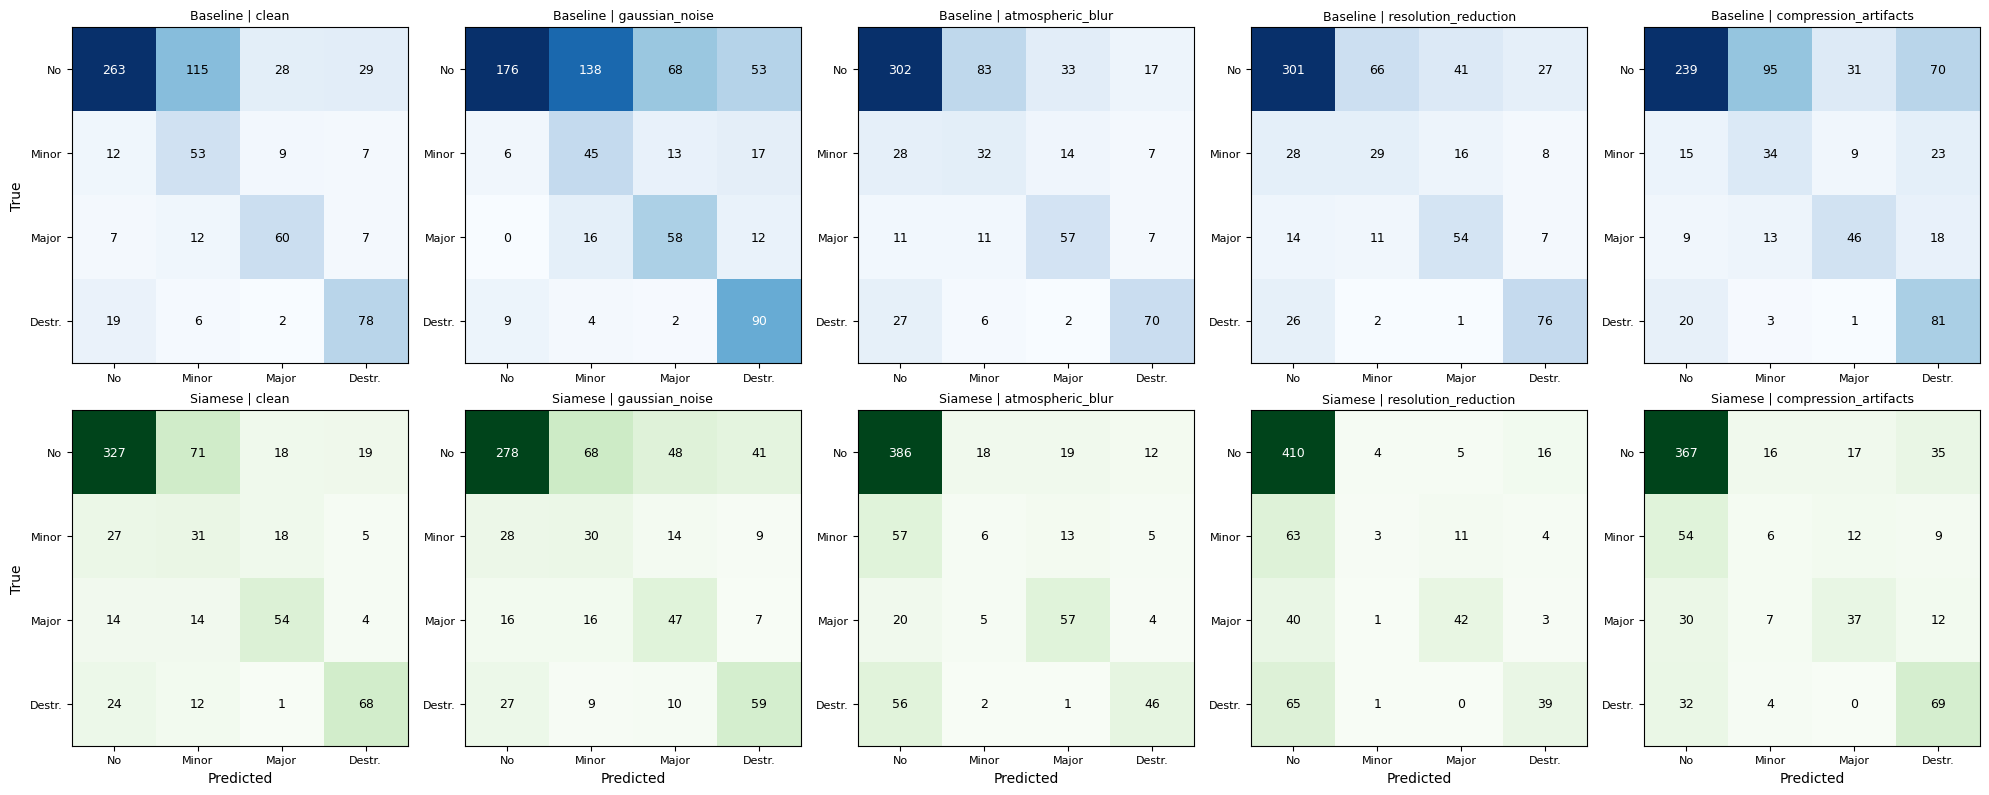


=== PER-CLASS PRECISION / RECALL / F1 ===
             Test set              Model        Class  Precision  Recall     F1  Support
                clean Baseline ResNet-50    no-damage     0.8738  0.6046 0.7147      435
                clean Baseline ResNet-50 minor-damage     0.2849  0.6543 0.3970       81
                clean Baseline ResNet-50 major-damage     0.6061  0.6977 0.6486       86
                clean Baseline ResNet-50    destroyed     0.6446  0.7429 0.6903      105
                clean  Siamese ResNet-50    no-damage     0.8342  0.7517 0.7908      435
                clean  Siamese ResNet-50 minor-damage     0.2422  0.3827 0.2967       81
                clean  Siamese ResNet-50 major-damage     0.5934  0.6279 0.6102       86
                clean  Siamese ResNet-50    destroyed     0.7083  0.6476 0.6766      105
       gaussian_noise Baseline ResNet-50    no-damage     0.9215  0.4046 0.5623      435
       gaussian_noise Baseline ResNet-50 minor-damage     0.2217  0

In [ ]:


robustness_results = []

for kind in degradation_types:

    print(f"\nEvaluating degradation: {kind}")

    degraded_dataset = XBDDegradedPairDataset(
        test_df,
        degradation_type=kind,
        transform=image_transform
    )

    degraded_loader = DataLoader(
        degraded_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    baseline_results, _, _ = evaluate_model(
        baseline_model,
        degraded_loader,
        "baseline"
    )

    siamese_results, _, _ = evaluate_model(
        siamese_model,
        degraded_loader,
        "siamese"
    )

    robustness_results.append({
        "Degradation": kind,
        "Model": "Baseline ResNet-50",
        **baseline_results
    })

    robustness_results.append({
        "Degradation": kind,
        "Model": "Siamese ResNet-50",
        **siamese_results
    })

    print(
        "Baseline Accuracy:",
        round(baseline_results["accuracy"], 4)
    )

    print(
        "Siamese Accuracy:",
        round(siamese_results["accuracy"], 4)
    )

robustness_df = pd.DataFrame(robustness_results)

# Per-class precision, recall, F1 and confusion matrix for every test set (clean + 4 degradations)
from sklearn.metrics import precision_recall_fscore_support
per_class_rows = []
cm_rows = []
cms = {}
test_sets = [("clean", test_loader)] + [
    (k, DataLoader(XBDDegradedPairDataset(test_df, k, image_transform),
                   batch_size=BATCH_SIZE, shuffle=False, num_workers=0))
    for k in degradation_types
]
for set_name, loader in test_sets:
    for model_name, model, mtype in [("Baseline ResNet-50", baseline_model, "baseline"),
                                     ("Siamese ResNet-50", siamese_model, "siamese")]:
        _, y_true, y_pred = evaluate_model(model, loader, mtype)
        p, r, f, n = precision_recall_fscore_support(
            y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0)
        for ci, cname in enumerate(CLASS_NAMES):
            per_class_rows.append({"Test set": set_name, "Model": model_name, "Class": cname,
                                   "Precision": round(p[ci], 4), "Recall": round(r[ci], 4),
                                   "F1": round(f[ci], 4), "Support": int(n[ci])})
        cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
        cms[(set_name, model_name)] = cm
        for ti, tname in enumerate(CLASS_NAMES):
            cm_rows.append({"Test set": set_name, "Model": model_name, "True class": tname,
                            **{f"Pred {pn}": int(cm[ti, pi]) for pi, pn in enumerate(CLASS_NAMES)}})

per_class_df = pd.DataFrame(per_class_rows)
per_class_df.to_csv(PROJECT_DIR / "per_class_metrics.csv", index=False)
pd.DataFrame(cm_rows).to_csv(PROJECT_DIR / "confusion_matrices_all.csv", index=False)

# Figure: confusion matrices for all 5 test sets, both models
import matplotlib.pyplot as plt
short = ["No", "Minor", "Major", "Destr."]
fig, axes = plt.subplots(2, len(test_sets), figsize=(4 * len(test_sets), 8))
for col, (set_name, _) in enumerate(test_sets):
    for row, model_name in enumerate(["Baseline ResNet-50", "Siamese ResNet-50"]):
        ax = axes[row, col]; cm = cms[(set_name, model_name)]
        ax.imshow(cm, cmap="Blues" if row == 0 else "Greens")
        for ti in range(NUM_CLASSES):
            for pi in range(NUM_CLASSES):
                ax.text(pi, ti, cm[ti, pi], ha="center", va="center", fontsize=9,
                        color="white" if cm[ti, pi] > cm.max() / 2 else "black")
        ax.set_xticks(range(NUM_CLASSES), short, fontsize=8)
        ax.set_yticks(range(NUM_CLASSES), short, fontsize=8)
        ax.set_title(f"{model_name.split()[0]} | {set_name}", fontsize=9)
        if col == 0: ax.set_ylabel("True")
        if row == 1: ax.set_xlabel("Predicted")
plt.tight_layout()
plt.savefig(PROJECT_DIR / "confusion_matrices_all_test_sets.png", dpi=200)
plt.show()

print("\n=== PER-CLASS PRECISION / RECALL / F1 ===")
print(per_class_df.to_string(index=False))

robustness_path = (
    PROJECT_DIR / "robustness_results.csv"
)

robustness_df.to_csv(
    robustness_path,
    index=False
)

print("\n=== ROBUSTNESS RESULTS ===")
print(robustness_df.to_string(index=False))

print("\nResults saved to:", robustness_path)

## 24. Training Performance Visualization

This cell plots the training and validation loss curves for both models to examine their learning performance.

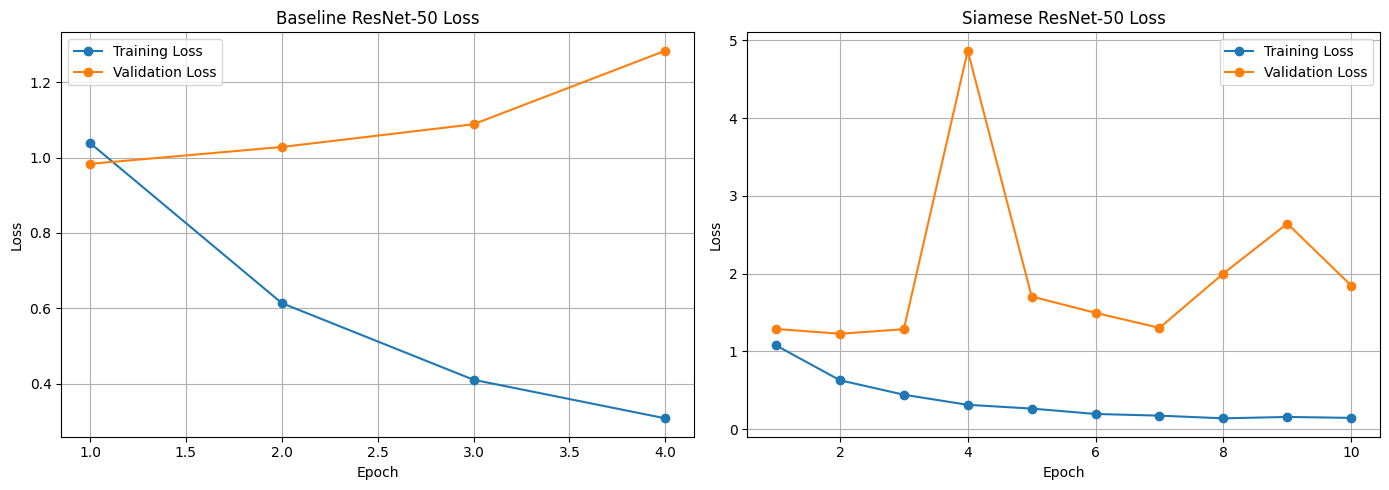

In [ ]:


import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    baseline_history_df["epoch"],
    baseline_history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    baseline_history_df["epoch"],
    baseline_history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Baseline ResNet-50 Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


axes[1].plot(
    siamese_history_df["epoch"],
    siamese_history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[1].plot(
    siamese_history_df["epoch"],
    siamese_history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[1].set_title("Siamese ResNet-50 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 25. Confusion Matrix Analysis

This cell generates confusion matrices for both models to visualize their classification performance across the four damage classes.

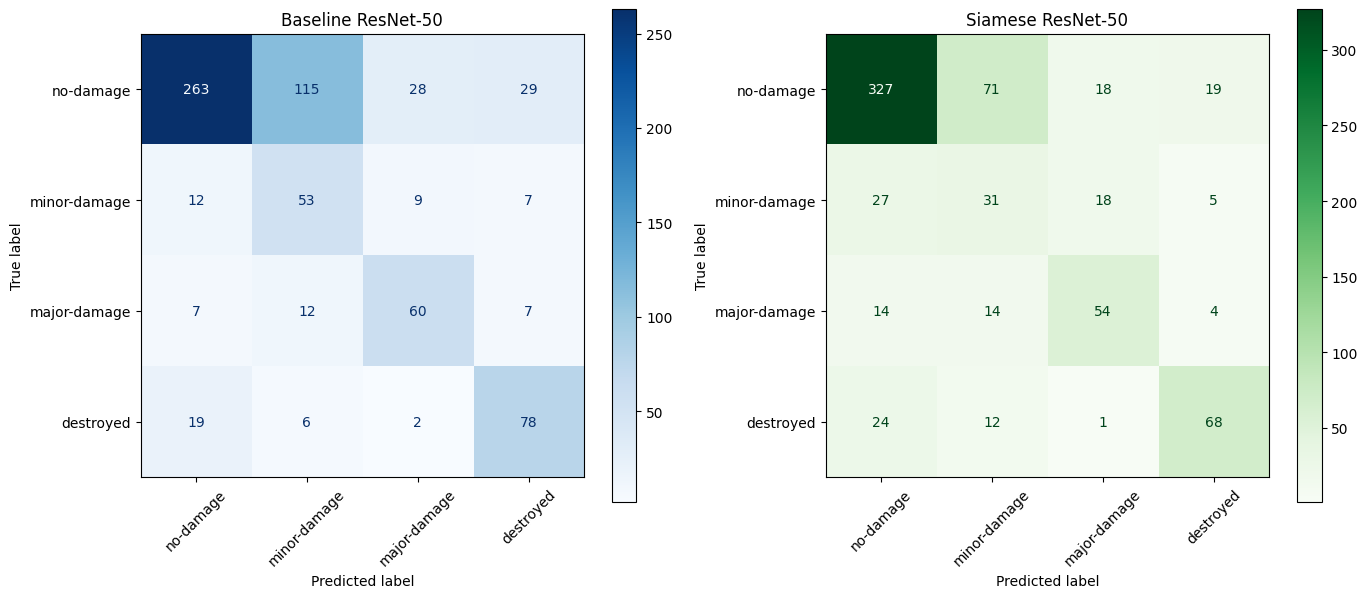

In [ ]:


import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay.from_predictions(
    baseline_labels,
    baseline_predictions,
    labels=list(range(NUM_CLASSES)),
    display_labels=CLASS_NAMES,
    cmap="Blues",
    ax=axes[0],
    xticks_rotation=45
)

axes[0].set_title("Baseline ResNet-50")

ConfusionMatrixDisplay.from_predictions(
    siamese_labels,
    siamese_predictions,
    labels=list(range(NUM_CLASSES)),
    display_labels=CLASS_NAMES,
    cmap="Greens",
    ax=axes[1],
    xticks_rotation=45
)

axes[1].set_title("Siamese ResNet-50")

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 26. Save Final Experimental Results

This cell saves the final model performance metrics, training history, robustness results, and experiment summary files.

In [ ]:


import json
from pathlib import Path

final_summary = {
    "project": "xBD Building Damage Assessment",
    "seed": SEED,
    "device": str(DEVICE),
    "epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "max_epochs": NUM_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "class_weights": dict(zip(CLASS_NAMES, [float(w) for w in CLASS_WEIGHTS])),
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "train_samples": len(train_dataset),
    "validation_samples": len(val_dataset),
    "test_samples": len(test_dataset),
    "baseline_test": baseline_test_results,
    "siamese_test": siamese_test_results,
    "best_baseline_validation_f1": best_baseline_f1,
    "best_siamese_validation_f1": best_siamese_f1,
    "best_baseline_epoch": best_baseline_epoch,
    "best_siamese_epoch": best_siamese_epoch,
    "baseline_training_minutes": baseline_minutes,
    "siamese_training_minutes": siamese_minutes
}

summary_path = PROJECT_DIR / "final_experiment_summary.json"

with open(summary_path, "w") as f:
    json.dump(final_summary, f, indent=4)

print("=== FINAL PROJECT RESULTS ===")

print("\nBaseline ResNet-50:")
for metric, value in baseline_test_results.items():
    print(f"{metric}: {value:.4f}")

print("\nSiamese ResNet-50:")
for metric, value in siamese_test_results.items():
    print(f"{metric}: {value:.4f}")

print("\nSaved experiment files:")

output_files = [
    "baseline_resnet50.pth",
    "siamese_resnet50.pth",
    "baseline_training_history.csv",
    "siamese_training_history.csv",
    "clean_test_comparison.csv",
    "robustness_results.csv",
    "training_curves.png",
    "confusion_matrices.png",
    "final_experiment_summary.json"
]

for filename in output_files:
    file_path = PROJECT_DIR / filename
    print(
        filename,
        "OK" if file_path.exists() else "MISSING"
    )

print("\nFinal experiment summary saved:", summary_path)

=== FINAL PROJECT RESULTS ===

Baseline ResNet-50:
loss: 0.8932
accuracy: 0.6421
precision_macro: 0.6023
recall_macro: 0.6749
f1_macro: 0.6126
f1_weighted: 0.6666

Siamese ResNet-50:
loss: 1.3202
accuracy: 0.6789
precision_macro: 0.5945
recall_macro: 0.6025
f1_macro: 0.5936
f1_weighted: 0.6953

Saved experiment files:
baseline_resnet50.pth OK
siamese_resnet50.pth OK
baseline_training_history.csv OK
siamese_training_history.csv OK
clean_test_comparison.csv OK
robustness_results.csv OK
training_curves.png OK
confusion_matrices.png OK
final_experiment_summary.json OK

Final experiment summary saved: /content/final_data/final_experiment_summary.json


## 27. Export Results to Google Drive

This cell copies the trained models, evaluation results, summary files, and generated figures to Google Drive for storage and future use.

In [ ]:
DRIVE_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
copied = []
for f in PROJECT_DIR.iterdir():
    if f.is_file() and f.suffix in {".csv", ".json", ".png", ".pth"}:
        shutil.copy2(f, DRIVE_RESULTS_DIR / f.name)
        copied.append(f.name)
print("Copied to", DRIVE_RESULTS_DIR)
for name in sorted(copied):
    print(" -", name)


Copied to /content/drive/MyDrive/CAI421_final_results_v2
 - baseline_resnet50.pth
 - baseline_training_history.csv
 - building_manifest.csv
 - building_manifest_with_splits.csv
 - class_distribution.csv
 - clean_test_comparison.csv
 - confusion_matrices.png
 - confusion_matrices_all.csv
 - confusion_matrices_all_test_sets.png
 - dataset_summary.csv
 - degradation_verification.csv
 - final_experiment_summary.json
 - per_class_metrics.csv
 - robustness_results.csv
 - siamese_resnet50.pth
 - siamese_training_history.csv
 - split_class_distribution.csv
 - training_curves.png
